# Metro Transfer Simulator

*Provenance: AI-generated.*

Discrete-event simulation of Lanka Metro Transit bus transfers at Borella, Colombo (routes CM01 and CM03) for a two-way Kadawatha - Pettah through-ticket.

In [16]:
import io
from pathlib import Path
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

SEED = 42
root_seed_sequence = np.random.SeedSequence(SEED)

print(f"SEED = {SEED}")
print(f"numpy {np.__version__}, scipy {scipy.__version__}, matplotlib {matplotlib.__version__}, pandas {pd.__version__}")

SEED = 42
numpy 2.4.6, scipy 1.16.3, matplotlib 3.10.0, pandas 2.2.3


## 1. Problem and question

*Provenance: AI-generated.*

Two Lanka Metro Transit routes intersect at Borella, Colombo: **CM01** (Makumbura - Colombo Fort/Pettah) and **CM03** (Makumbura - Kadawatha). No direct route links Kadawatha and Pettah. We evaluate a through-ticket with one transfer at Borella in both directions simultaneously:

- **Group A (Kadawatha to Pettah):** feeder `CM03` towards Makumbura, connecting to `CM01` towards Colombo Fort.
- **Group B (Pettah to Kadawatha):** feeder `CM01` towards Makumbura, connecting to `CM03` towards Kadawatha.

**Research question:** What holding rule and route-level timetable adjustment at Borella keep missed connections low for both groups without imposing excessive holding delay on on-board passengers?

## 2. Model, assumptions and equations

*Provenance: AI-generated.*

### Timetable cleaning and Borella interpolation

- **Data anomaly (`CM03-MAK-02`):** In `cm03_makumbura_to_kadawatha.csv`, trip `CM03-MAK-02` (05:45 from Makumbura) has a +60-minute offset on intermediate stops (`Nawinna` through `Kelaniya University`), while the terminal arrival at `Kadawatha` (08:05) matches the standard 140-minute total runtime. We subtract 60 minutes from those four intermediate timepoints and assert strict monotonicity.
- **Borella interpolation (placeholder):** Borella is not a published timepoint. For a trip with bracketing timepoint scheduled times $T_{\text{prev}}$ and $T_{\text{next}}$, we interpolate:

$$T_{\text{Borella}} = T_{\text{prev}} + \lambda \left(T_{\text{next}} - T_{\text{prev}}\right)$$

  using placeholder $\lambda = 0.5$ until exact stop-to-stop distances are measured.
- **Target connector mapping:** With placeholder walking time $w = 3.5\text{ min}$, each feeder $f$ has scheduled ready time $T_{f,\text{ready}} = T_{f,\text{Borella}} + w$, and targets the earliest opposite-direction connector $c(f)$ with $T_{c,\text{Borella}} \ge T_{f,\text{ready}}$ (or `out_of_window` if none exists).

### Traffic layer (Markov chain and random variate generation)

- **Discrete-time Markov chain:** Each road corridor evolves over three congestion states $S_t \in \{0:\text{Free},\, 1:\text{Slow},\, 2:\text{Jammed}\}$ with state speeds $v = (30, 15, 5)\text{ km/h}$ and step size $\Delta t = 5\text{ min}$. Peak periods are 06:00-09:00 and 17:00-20:00.
- **Parametric transition matrix:** Controlled by a single jam-tendency parameter $p \in [0.01, 0.85]$:

$$P(p) = \begin{pmatrix} 1 - p & 0.7p & 0.3p \\ 0.4(1 - p) & 0.4 & 0.2 + 0.4p \\ 0.1(1 - p) & 0.3(1 - p) & 0.6 + 0.4p \end{pmatrix}$$

- **Stationary distribution and calibration:** The stationary distribution $\pi^*$ satisfies $\pi^* P = \pi^*$ and $\sum_s \pi^*_s = 1$, giving expected speed $\bar{v}(p) = \sum_s \pi^*_s v_s$. Given a target mean speed $v_{\text{target}} \in [\bar{v}(0.85), \bar{v}(0.01)]$, $p$ is solved by bisection.
- **Explicit discrete variate generation:** Given current state $i$ and $U \sim \text{Uniform}(0, 1)$, the next state $j$ is sampled via cumulative row probability lookup:

$$j = \min\left\{ k \in \{0, 1, 2\} : \sum_{m=0}^{k} P_{i,m} \ge U \right\}$$

### Bus journey, passenger arrivals, and dwell time

- **Explicit Poisson arrivals:** At each stop $s$, passenger inter-arrival times are generated from $U \sim \text{Uniform}(0, 1)$ via inverse transform:

$$\Delta \tau = -\frac{\ln(1 - U)}{\lambda_s(t)}$$

- **Downstream destinations:** Each boarding passenger's destination is sampled uniformly over the remaining downstream stops of the route.
- **Dwell time and capacity:** At stop $s$ with $a_s$ alighting and $b_s$ boarding passengers (capped by bus capacity $C = 80$, with excess passengers remaining in the stop queue for the next bus):

$$t_{\text{dwell}} = \frac{t_{\text{door}} + t_{\text{alight}}\, a_s + t_{\text{board}}\, b_s}{60}\quad [\text{min}]$$

### Borella transfer, holding rules, and objective

- **Transfer arrivals:** Each feeder trip $f$ brings $m_f \sim \text{Poisson}(5)$ transfer passengers who become ready at $T_{f,\text{ready}} = T_{f,\text{arr,Borella}} + w$.
- **Connector departure rules:** Let $T_{c,\text{base}} = \max(T_{c,\text{sched}}, T_{c,\text{arr}} + t_{c,\text{dwell}})$.
  - `none`: departs at $T_{c,\text{base}}$ ($\text{hold}_c = 0$).
  - `schedule`: if any protected feeder $f$ with $c(f) = c$ is not yet ready at $T_{c,\text{base}}$, the connector holds up to $T_{c,\text{sched}} + h$, departing as soon as all protected feeders are ready or the cap is reached.
- **Objective:** Equivalent passenger-minutes combining Borella transfer wait and on-board holding delay ($w_{\text{wait}} = 2.0$, $w_{\text{hold}} = 1.0$):

$$J(h, \Delta) = w_{\text{wait}}\, \mathbb{E}\left[\sum_i W_i\right] + w_{\text{hold}}\, \mathbb{E}\left[\sum_b N_b \cdot \text{hold}_b\right]$$

## 3. Implementation

*Provenance: AI-generated.*

In [17]:
WALK_TIME_PLACEHOLDER_MIN = 3.5
BORELLA_INTERPOLATION_PLACEHOLDER = 0.5

EMBEDDED_TIMETABLES = {
    "cm01_makumbura_to_fort.csv": (
        "trip_id,Makumbura,Sethsiripaya,Rajagiriya,Town Hall,Colombo Fort\n"
        "CM01-MAK-01,05:30,06:22,06:37,07:01,07:20\n"
        "CM01-MAK-02,06:15,07:07,07:22,07:46,08:05\n"
        "CM01-MAK-03,06:45,07:37,07:52,08:16,08:35\n"
        "CM01-MAK-04,07:15,08:07,08:22,08:46,09:05\n"
        "CM01-MAK-05,08:15,09:07,09:22,09:46,10:05\n"
        "CM01-MAK-06,09:45,10:37,10:52,11:16,11:35\n"
        "CM01-MAK-07,10:45,11:37,11:52,12:16,12:35\n"
        "CM01-MAK-08,12:15,13:07,13:22,13:46,14:05\n"
        "CM01-MAK-09,13:30,14:22,14:37,15:01,15:20\n"
        "CM01-MAK-10,14:30,15:22,15:37,16:01,16:20\n"
        "CM01-MAK-11,15:30,16:22,16:37,17:01,17:20\n"
        "CM01-MAK-12,16:30,17:22,17:37,18:01,18:20\n"
    ),
    "cm01_fort_to_makumbura.csv": (
        "trip_id,Colombo Fort,Pettah,Town Hall,Rajagiriya,Sethsiripaya,Makumbura\n"
        "CM01-FOR-01,07:30,07:32,07:49,08:13,08:28,09:20\n"
        "CM01-FOR-02,08:15,08:17,08:34,08:58,09:13,10:05\n"
        "CM01-FOR-03,08:45,08:47,09:04,09:28,09:43,10:35\n"
        "CM01-FOR-04,09:30,09:32,09:49,10:13,10:28,11:20\n"
        "CM01-FOR-05,10:30,10:32,10:49,11:13,11:28,12:20\n"
        "CM01-FOR-06,12:00,12:02,12:19,12:43,12:58,13:50\n"
        "CM01-FOR-07,13:30,13:32,13:49,14:13,14:28,15:20\n"
        "CM01-FOR-08,14:30,14:32,14:49,15:13,15:28,16:20\n"
        "CM01-FOR-09,15:30,15:32,15:49,16:13,16:28,17:20\n"
        "CM01-FOR-10,16:30,16:32,16:49,17:13,17:28,18:20\n"
        "CM01-FOR-11,17:30,17:32,17:49,18:13,18:28,19:20\n"
        "CM01-FOR-12,18:30,18:32,18:49,19:13,19:28,20:20\n"
    ),
    "cm03_makumbura_to_kadawatha.csv": (
        "trip_id,Makumbura,Apeksha Hospital,Nawinna,Narahenpita Junction,Cambell Park,Kelaniya University,Kadawatha\n"
        "CM03-MAK-01,05:00,05:25,05:33,06:05,06:33,07:02,07:20\n"
        "CM03-MAK-02,05:45,06:10,07:18,07:50,08:18,08:47,08:05\n"
        "CM03-MAK-03,07:00,07:25,07:33,08:05,08:33,09:02,09:20\n"
        "CM03-MAK-04,08:00,08:25,08:33,09:05,09:33,10:02,10:20\n"
        "CM03-MAK-05,09:00,09:25,09:33,10:05,10:33,11:02,11:20\n"
        "CM03-MAK-06,11:00,11:25,11:33,12:05,12:33,13:02,13:20\n"
        "CM03-MAK-07,12:00,12:25,12:33,13:05,13:33,14:02,14:20\n"
        "CM03-MAK-08,13:00,13:25,13:33,14:05,14:33,15:02,15:20\n"
        "CM03-MAK-09,14:00,14:25,14:33,15:05,15:33,16:02,16:20\n"
        "CM03-MAK-10,15:00,15:25,15:33,16:05,16:33,17:02,17:20\n"
        "CM03-MAK-11,16:15,16:40,16:48,17:20,17:48,18:17,18:35\n"
        "CM03-MAK-12,17:15,17:40,17:48,18:20,18:48,19:17,19:35\n"
    ),
    "cm03_kadawatha_to_makumbura.csv": (
        "trip_id,Kadawatha,Kelaniya University,Cambell Park,Narahenpita Junction,Nawinna,Apeksha Hospital,Makumbura\n"
        "CM03-KAD-01,07:45,08:03,08:32,09:00,09:32,09:40,10:05\n"
        "CM03-KAD-02,09:45,10:03,10:32,11:00,11:32,11:40,12:05\n"
        "CM03-KAD-03,10:45,11:03,11:32,12:00,12:32,12:40,13:05\n"
        "CM03-KAD-04,11:45,12:03,12:32,13:00,13:32,13:40,14:05\n"
        "CM03-KAD-05,13:45,14:03,14:32,15:00,15:32,15:40,16:05\n"
        "CM03-KAD-06,14:45,15:03,15:32,16:00,16:32,16:40,17:05\n"
        "CM03-KAD-07,15:45,16:03,16:32,17:00,17:32,17:40,18:05\n"
        "CM03-KAD-08,16:45,17:03,17:32,18:00,18:32,18:40,19:05\n"
        "CM03-KAD-09,17:45,18:03,18:32,19:00,19:32,19:40,20:05\n"
        "CM03-KAD-10,19:15,19:33,20:02,20:30,21:02,21:10,21:35\n"
        "CM03-KAD-11,19:45,20:03,20:32,21:00,21:32,21:40,22:05\n"
    ),
}


def parse_hhmm_to_minutes(hhmm_str):
    hours, minutes = map(int, hhmm_str.strip().split(":"))
    return float(hours * 60 + minutes)


def format_minutes_to_hhmm(total_min):
    if pd.isna(total_min):
        return "--:--"
    rounded_min = int(round(total_min))
    return f"{rounded_min // 60:02d}:{rounded_min % 60:02d}"


def load_raw_timetable(filename):
    for candidate in (Path("data/timetables") / filename, Path("../data/timetables") / filename):
        if candidate.exists():
            return pd.read_csv(candidate), str(candidate)
    return pd.read_csv(io.StringIO(EMBEDDED_TIMETABLES[filename])), "embedded"


def convert_timetable_to_minutes(df):
    result = df.copy()
    for col in result.columns:
        if col != "trip_id":
            result[col] = result[col].map(parse_hhmm_to_minutes)
    return result


def clean_cm03_mak_to_kad(df):
    cleaned = df.copy()
    cleaning_log = []
    shifted_cols = ["Nawinna", "Narahenpita Junction", "Cambell Park", "Kelaniya University"]
    mask = cleaned["trip_id"] == "CM03-MAK-02"
    if mask.any():
        for col in shifted_cols:
            before_str = format_minutes_to_hhmm(cleaned.loc[mask, col].iloc[0])
            cleaned.loc[mask, col] = cleaned.loc[mask, col] - 60.0
            after_str = format_minutes_to_hhmm(cleaned.loc[mask, col].iloc[0])
            cleaning_log.append(f"CM03-MAK-02 {col}: {before_str} -> {after_str} (-60 min offset)")
    timepoint_cols = [c for c in cleaned.columns if c != "trip_id"]
    diffs = cleaned[timepoint_cols].diff(axis=1).iloc[:, 1:]
    assert (diffs > 0).all().all(), "Non-monotonic timepoints remain after cleaning"
    return cleaned, cleaning_log


def build_borella_schedule(df, prev_stop, next_stop, fraction, leg_name):
    out = pd.DataFrame({
        "leg": leg_name,
        "trip_id": df["trip_id"],
        "origin_sched_min": df[df.columns[1]],
        "borella_sched_min": df[prev_stop] + fraction * (df[next_stop] - df[prev_stop]),
        "dest_sched_min": df[df.columns[-1]],
    })
    out["borella_sched_hhmm"] = out["borella_sched_min"].map(format_minutes_to_hhmm)
    return out


def map_target_connectors(feeders_df, connectors_df, walk_time_min, group_name):
    conn_sorted = connectors_df.sort_values("borella_sched_min").reset_index(drop=True)
    rows = []
    for _, feeder in feeders_df.sort_values("borella_sched_min").iterrows():
        ready_min = feeder["borella_sched_min"] + walk_time_min
        eligible = conn_sorted[conn_sorted["borella_sched_min"] >= ready_min]
        if eligible.empty:
            target_id = None
            target_borella_min = np.nan
            slack_min = np.nan
            status = "out_of_window"
        else:
            target = eligible.iloc[0]
            target_id = target["trip_id"]
            target_borella_min = target["borella_sched_min"]
            slack_min = target_borella_min - ready_min
            status = "in_window"
        rows.append({
            "group": group_name,
            "feeder_trip_id": feeder["trip_id"],
            "feeder_borella_hhmm": feeder["borella_sched_hhmm"],
            "ready_hhmm": format_minutes_to_hhmm(ready_min),
            "target_connector_id": target_id,
            "connector_borella_hhmm": format_minutes_to_hhmm(target_borella_min),
            "scheduled_slack_min": slack_min,
            "window_status": status,
        })
    return pd.DataFrame(rows)


raw_cm01_mak, src_1 = load_raw_timetable("cm01_makumbura_to_fort.csv")
raw_cm01_for, src_2 = load_raw_timetable("cm01_fort_to_makumbura.csv")
raw_cm03_mak, src_3 = load_raw_timetable("cm03_makumbura_to_kadawatha.csv")
raw_cm03_kad, src_4 = load_raw_timetable("cm03_kadawatha_to_makumbura.csv")

cm01_mak_min = convert_timetable_to_minutes(raw_cm01_mak)
cm01_for_min = convert_timetable_to_minutes(raw_cm01_for)
cm03_mak_min_raw = convert_timetable_to_minutes(raw_cm03_mak)
cm03_kad_min = convert_timetable_to_minutes(raw_cm03_kad)

cm03_mak_min, cleaning_log = clean_cm03_mak_to_kad(cm03_mak_min_raw)

sched_cm01_mak = build_borella_schedule(cm01_mak_min, "Rajagiriya", "Town Hall", BORELLA_INTERPOLATION_PLACEHOLDER, "CM01_MAK_to_FOR")
sched_cm01_for = build_borella_schedule(cm01_for_min, "Town Hall", "Rajagiriya", BORELLA_INTERPOLATION_PLACEHOLDER, "CM01_FOR_to_MAK")
sched_cm03_mak = build_borella_schedule(cm03_mak_min, "Narahenpita Junction", "Cambell Park", BORELLA_INTERPOLATION_PLACEHOLDER, "CM03_MAK_to_KAD")
sched_cm03_kad = build_borella_schedule(cm03_kad_min, "Cambell Park", "Narahenpita Junction", BORELLA_INTERPOLATION_PLACEHOLDER, "CM03_KAD_to_MAK")

transfers_group_a = map_target_connectors(sched_cm03_kad, sched_cm01_mak, WALK_TIME_PLACEHOLDER_MIN, "A_Kadawatha_to_Pettah")
transfers_group_b = map_target_connectors(sched_cm01_for, sched_cm03_mak, WALK_TIME_PLACEHOLDER_MIN, "B_Pettah_to_Kadawatha")

print("Data sources:", [src_1, src_2, src_3, src_4])
print("Cleaning log:", cleaning_log)
print(f"Group A in-window: {(transfers_group_a['window_status'] == 'in_window').sum()}/{len(transfers_group_a)}")
print(f"Group B in-window: {(transfers_group_b['window_status'] == 'in_window').sum()}/{len(transfers_group_b)}")

Data sources: ['embedded', 'embedded', 'embedded', 'embedded']
Cleaning log: ['CM03-MAK-02 Nawinna: 07:18 -> 06:18 (-60 min offset)', 'CM03-MAK-02 Narahenpita Junction: 07:50 -> 06:50 (-60 min offset)', 'CM03-MAK-02 Cambell Park: 08:18 -> 07:18 (-60 min offset)', 'CM03-MAK-02 Kelaniya University: 08:47 -> 07:47 (-60 min offset)']
Group A in-window: 7/11
Group B in-window: 11/12


In [18]:
STATE_NAMES = ("Free", "Slow", "Jammed")
STATE_SPEEDS_KMPH = np.array([30.0, 15.0, 5.0])
TRAFFIC_STEP_MIN = 5.0
JAM_PARAM_MIN = 0.01
JAM_PARAM_MAX = 0.85
PEAK_WINDOWS_MIN = ((360.0, 540.0), (1020.0, 1200.0))

SYNTHETIC_TARGET_SPEED_OFFPEAK_KMPH = 22.0
SYNTHETIC_TARGET_SPEED_PEAK_KMPH = 14.0


def build_parametric_transition_matrix(jam_param):
    p = float(jam_param)
    matrix = np.array([
        [1.0 - p,       0.7 * p,       0.3 * p],
        [0.4 * (1 - p), 0.4,           0.2 + 0.4 * p],
        [0.1 * (1 - p), 0.3 * (1 - p), 0.6 + 0.4 * p],
    ], dtype=float)
    assert np.allclose(matrix.sum(axis=1), 1.0), "Transition rows must sum to 1"
    return matrix


def compute_stationary_distribution(transition_matrix):
    n_states = transition_matrix.shape[0]
    system_matrix = transition_matrix.T - np.eye(n_states)
    system_matrix[-1, :] = 1.0
    rhs = np.zeros(n_states)
    rhs[-1] = 1.0
    pi_star = np.linalg.solve(system_matrix, rhs)
    assert np.all(pi_star >= -1e-12) and np.isclose(pi_star.sum(), 1.0)
    return np.clip(pi_star, 0.0, 1.0)


def expected_speed_for_jam_param(jam_param, state_speeds_kmph=STATE_SPEEDS_KMPH):
    matrix = build_parametric_transition_matrix(jam_param)
    pi_star = compute_stationary_distribution(matrix)
    return float(np.dot(pi_star, state_speeds_kmph))


def calibrate_jam_param_bisection(target_speed_kmph, p_low=JAM_PARAM_MIN, p_high=JAM_PARAM_MAX, tol=1e-6):
    v_max = expected_speed_for_jam_param(p_low)
    v_min = expected_speed_for_jam_param(p_high)
    assert v_min <= target_speed_kmph <= v_max, (
        f"Target speed {target_speed_kmph:.2f} km/h outside reachable bracket [{v_min:.2f}, {v_max:.2f}]"
    )
    low, high = p_low, p_high
    for _ in range(80):
        mid = 0.5 * (low + high)
        if expected_speed_for_jam_param(mid) > target_speed_kmph:
            low = mid
        else:
            high = mid
        if high - low < tol:
            break
    return 0.5 * (low + high)


def sample_discrete_state(cdf_row, uniform_draw):
    for state_idx, cum_prob in enumerate(cdf_row):
        if uniform_draw <= cum_prob:
            return state_idx
    return len(cdf_row) - 1


def simulate_markov_chain(transition_matrix, n_steps, rng, initial_state=0):
    cdf = np.cumsum(transition_matrix, axis=1)
    uniforms = rng.random(n_steps)
    states = np.empty(n_steps, dtype=int)
    state = initial_state
    for step in range(n_steps):
        states[step] = state
        state = sample_discrete_state(cdf[state], uniforms[step])
    return states


def is_peak_time(time_min):
    return any(start <= time_min < end for start, end in PEAK_WINDOWS_MIN)


p_offpeak = calibrate_jam_param_bisection(SYNTHETIC_TARGET_SPEED_OFFPEAK_KMPH)
p_peak = calibrate_jam_param_bisection(SYNTHETIC_TARGET_SPEED_PEAK_KMPH)

P_offpeak = build_parametric_transition_matrix(p_offpeak)
P_peak = build_parametric_transition_matrix(p_peak)

pi_offpeak = compute_stationary_distribution(P_offpeak)
pi_peak = compute_stationary_distribution(P_peak)

print(f"Calibrated off-peak jam param p = {p_offpeak:.4f}, pi* = {np.round(pi_offpeak, 4)}, E[v] = {np.dot(pi_offpeak, STATE_SPEEDS_KMPH):.2f} km/h")
print(f"Calibrated peak     jam param p = {p_peak:.4f}, pi* = {np.round(pi_peak, 4)}, E[v] = {np.dot(pi_peak, STATE_SPEEDS_KMPH):.2f} km/h")

Calibrated off-peak jam param p = 0.1359, pi* = [0.6056 0.1861 0.2084], E[v] = 22.00 km/h
Calibrated peak     jam param p = 0.3753, pi* = [0.255  0.2624 0.4826], E[v] = 14.00 km/h


In [19]:
CAPACITY_PAX = 80
DOOR_TIME_SEC = 12.0
BOARD_TIME_SEC = 3.0
ALIGHT_TIME_SEC = 2.0
BUS_SPEED_FACTOR_ALPHA = 0.75
DAY_START_MIN = 240.0
DAY_END_MIN = 1380.0
ARRIVAL_WINDOW_START_MIN = 270.0

ROUTE_LEGS_CONFIG = {
    "CM01_MAK_to_FOR": {
        "stops": ["Makumbura", "Sethsiripaya", "Rajagiriya", "Borella (Singer Mega)", "Town Hall", "Colombo Fort"],
        "segment_distances_km": [12.5, 4.0, 2.5, 2.5, 3.0],
        "borella_idx": 3,
        "base_arrival_rate_pax_per_min": [0.65, 0.55, 0.50, 0.45, 0.25, 0.0],
    },
    "CM01_FOR_to_MAK": {
        "stops": ["Colombo Fort", "Pettah", "Town Hall", "Borella (Singer Mega)", "Rajagiriya", "Sethsiripaya", "Makumbura"],
        "segment_distances_km": [1.0, 2.5, 2.5, 2.5, 4.0, 12.5],
        "borella_idx": 3,
        "base_arrival_rate_pax_per_min": [0.55, 0.65, 0.50, 0.45, 0.35, 0.20, 0.0],
    },
    "CM03_MAK_to_KAD": {
        "stops": ["Makumbura", "Apeksha Hospital", "Nawinna", "Narahenpita Junction", "Borella 02 (YMBA)", "Cambell Park", "Kelaniya University", "Kadawatha"],
        "segment_distances_km": [6.5, 2.5, 7.0, 3.0, 2.5, 7.5, 4.5],
        "borella_idx": 4,
        "base_arrival_rate_pax_per_min": [0.60, 0.35, 0.35, 0.45, 0.45, 0.30, 0.25, 0.0],
    },
    "CM03_KAD_to_MAK": {
        "stops": ["Kadawatha", "Kelaniya University", "Cambell Park", "Borella 02 (YMBA)", "Narahenpita Junction", "Nawinna", "Apeksha Hospital", "Makumbura"],
        "segment_distances_km": [4.5, 7.5, 2.5, 3.0, 7.0, 2.5, 6.5],
        "borella_idx": 3,
        "base_arrival_rate_pax_per_min": [0.65, 0.45, 0.40, 0.45, 0.35, 0.25, 0.20, 0.0],
    },
}


def generate_daily_traffic_grid(rng, p_offpeak_mat, p_peak_mat):
    n_slots = int((DAY_END_MIN - DAY_START_MIN) / TRAFFIC_STEP_MIN) + 12
    cdf_offpeak = np.cumsum(p_offpeak_mat, axis=1)
    cdf_peak = np.cumsum(p_peak_mat, axis=1)
    uniforms = rng.random(n_slots)
    states = np.empty(n_slots, dtype=int)
    state = 0
    for slot in range(n_slots):
        states[slot] = state
        t_min = DAY_START_MIN + slot * TRAFFIC_STEP_MIN
        cdf = cdf_peak if is_peak_time(t_min) else cdf_offpeak
        state = sample_discrete_state(cdf[state], uniforms[slot])
    return states


def travel_segment_minutes(start_time_min, distance_km, traffic_states, alpha=BUS_SPEED_FACTOR_ALPHA):
    remaining_km = float(distance_km)
    current_time_min = float(start_time_min)
    while remaining_km > 1e-9:
        slot = int(max(0, (current_time_min - DAY_START_MIN) // TRAFFIC_STEP_MIN))
        slot = min(slot, len(traffic_states) - 1)
        slot_end_min = DAY_START_MIN + (slot + 1) * TRAFFIC_STEP_MIN
        avail_min = max(0.01, slot_end_min - current_time_min)
        speed_km_per_min = (alpha * STATE_SPEEDS_KMPH[traffic_states[slot]]) / 60.0
        max_dist_km = speed_km_per_min * avail_min
        if max_dist_km >= remaining_km:
            current_time_min += remaining_km / speed_km_per_min
            remaining_km = 0.0
        else:
            remaining_km -= max_dist_km
            current_time_min = slot_end_min
    return current_time_min - start_time_min


def sample_exponential_interarrival(rate_per_min, rng):
    u = rng.random()
    return -np.log(1.0 - min(u, 1.0 - 1e-12)) / rate_per_min


def sample_downstream_destination(stop_idx, n_stops, rng):
    n_downstream = n_stops - 1 - stop_idx
    u = rng.random()
    offset = min(int(u * n_downstream), n_downstream - 1)
    return stop_idx + 1 + offset


def generate_stop_arrivals(leg_cfg, arr_rng, dest_rng, end_time_min=DAY_END_MIN):
    n_stops = len(leg_cfg["stops"])
    queues = [[] for _ in range(n_stops)]
    for stop_idx in range(n_stops - 1):
        base_rate = leg_cfg["base_arrival_rate_pax_per_min"][stop_idx]
        if base_rate <= 0.0:
            continue
        t_min = ARRIVAL_WINDOW_START_MIN
        while t_min < end_time_min:
            rate = base_rate * (1.35 if is_peak_time(t_min) else 0.85)
            t_min += sample_exponential_interarrival(rate, arr_rng)
            if t_min < end_time_min:
                dest_idx = sample_downstream_destination(stop_idx, n_stops, dest_rng)
                queues[stop_idx].append((t_min, dest_idx))
    return queues


def simulate_leg_day(leg_name, sched_df, leg_cfg, traffic_states, arr_rng, dest_rng, capacity_pax=CAPACITY_PAX, alpha=BUS_SPEED_FACTOR_ALPHA):
    queues = generate_stop_arrivals(leg_cfg, arr_rng, dest_rng)
    queue_cursors = [0] * len(leg_cfg["stops"])
    n_stops = len(leg_cfg["stops"])
    borella_idx = leg_cfg["borella_idx"]
    trip_records = []

    for _, trip in sched_df.sort_values("origin_sched_min").iterrows():
        t_curr = float(trip["origin_sched_min"])
        onboard_dests = []
        total_left_behind = 0
        borella_arr_min = np.nan
        borella_onboard_pax = 0

        for stop_idx in range(n_stops):
            if stop_idx > 0:
                dist_km = leg_cfg["segment_distances_km"][stop_idx - 1]
                t_curr += travel_segment_minutes(t_curr, dist_km, traffic_states, alpha=alpha)

            n_alighting = sum(1 for d in onboard_dests if d == stop_idx)
            onboard_dests = [d for d in onboard_dests if d != stop_idx]

            q = queues[stop_idx]
            cursor = queue_cursors[stop_idx]
            waiting_count = 0
            while cursor + waiting_count < len(q) and q[cursor + waiting_count][0] <= t_curr:
                waiting_count += 1

            if capacity_pax is None:
                n_boarding = waiting_count
            else:
                free_seats = max(0, capacity_pax - len(onboard_dests))
                n_boarding = min(waiting_count, free_seats)

            left_here = waiting_count - n_boarding
            total_left_behind += left_here
            for k in range(n_boarding):
                onboard_dests.append(q[cursor + k][1])
            queue_cursors[stop_idx] = cursor + n_boarding

            if capacity_pax is not None:
                assert len(onboard_dests) <= capacity_pax, f"Capacity exceeded: {len(onboard_dests)} > {capacity_pax}"

            dwell_min = (DOOR_TIME_SEC + ALIGHT_TIME_SEC * n_alighting + BOARD_TIME_SEC * n_boarding) / 60.0
            if stop_idx == borella_idx:
                borella_arr_min = t_curr
                borella_onboard_pax = len(onboard_dests)
            t_curr += dwell_min

        trip_records.append({
            "leg": leg_name,
            "trip_id": trip["trip_id"],
            "borella_sched_hhmm": trip["borella_sched_hhmm"],
            "borella_sim_hhmm": format_minutes_to_hhmm(borella_arr_min),
            "borella_delay_min": round(borella_arr_min - trip["borella_sched_min"], 2),
            "borella_onboard_pax": borella_onboard_pax,
            "left_behind_pax": total_left_behind,
        })
    return pd.DataFrame(trip_records)


day_streams = root_seed_sequence.spawn(3)
traffic_rng = np.random.default_rng(day_streams[0])
arrivals_rng = np.random.default_rng(day_streams[1])
destinations_rng = np.random.default_rng(day_streams[2])

leg_schedules = {
    "CM01_MAK_to_FOR": sched_cm01_mak,
    "CM01_FOR_to_MAK": sched_cm01_for,
    "CM03_MAK_to_KAD": sched_cm03_mak,
    "CM03_KAD_to_MAK": sched_cm03_kad,
}

daily_traffic = {
    leg_name: generate_daily_traffic_grid(traffic_rng, P_offpeak, P_peak)
    for leg_name in ROUTE_LEGS_CONFIG
}

day_leg_results = {}
for leg_name, sched_df in leg_schedules.items():
    day_leg_results[leg_name] = simulate_leg_day(
        leg_name, sched_df, ROUTE_LEGS_CONFIG[leg_name], daily_traffic[leg_name], arrivals_rng, destinations_rng
    )
    print(f"\n--- {leg_name} (one simulated day) ---")
    print(day_leg_results[leg_name].to_string(index=False))


--- CM01_MAK_to_FOR (one simulated day) ---
            leg     trip_id borella_sched_hhmm borella_sim_hhmm  borella_delay_min  borella_onboard_pax  left_behind_pax
CM01_MAK_to_FOR CM01-MAK-01              06:49            06:29             -19.97                   80               35
CM01_MAK_to_FOR CM01-MAK-02              07:34            08:04              29.72                   80               97
CM01_MAK_to_FOR CM01-MAK-03              08:04            08:17              13.35                   80               42
CM01_MAK_to_FOR CM01-MAK-04              08:34            08:30              -4.46                   52                0
CM01_MAK_to_FOR CM01-MAK-05              09:34            10:11              37.10                   80               89
CM01_MAK_to_FOR CM01-MAK-06              11:04            10:43             -21.07                   80               69
CM01_MAK_to_FOR CM01-MAK-07              12:04            11:42             -21.57                   80     

In [20]:
import heapq

TRANSFER_MEAN_PAX = 5.0
WAIT_WEIGHT = 2.0
HOLD_WEIGHT = 1.0


def sample_poisson_knuth(mean_val, rng):
    limit = np.exp(-mean_val)
    k = 0
    prod = 1.0
    while True:
        k += 1
        prod *= rng.random()
        if prod <= limit:
            return k - 1


def build_target_lookup(transfers_df):
    return dict(zip(transfers_df["feeder_trip_id"], transfers_df["target_connector_id"]))


def calibrate_leg_alphas(n_cal_days=25, tol=0.01):
    cal_seeds = root_seed_sequence.spawn(n_cal_days)
    cal_grids = []
    for s in cal_seeds:
        sub = s.spawn(3)
        t_rng = np.random.default_rng(sub[0])
        a_rng = np.random.default_rng(sub[1])
        d_rng = np.random.default_rng(sub[2])
        cal_grids.append((t_rng, a_rng, d_rng))

    alphas = {}
    for leg_name, sched_df in leg_schedules.items():
        target_runtime_min = float((sched_df["borella_sched_min"] - sched_df["origin_sched_min"]).mean())
        low, high = 0.25, 2.50
        for _ in range(18):
            mid = 0.5 * (low + high)
            mean_delays = []
            for idx, s in enumerate(cal_seeds):
                sub = s.spawn(3)
                t_grid = generate_daily_traffic_grid(np.random.default_rng(sub[0]), P_offpeak, P_peak)
                sim_df = simulate_leg_day(
                    leg_name, sched_df, ROUTE_LEGS_CONFIG[leg_name], t_grid,
                    np.random.default_rng(sub[1]), np.random.default_rng(sub[2]), alpha=mid
                )
                mean_delays.append(sim_df["borella_delay_min"].mean())
            mean_err = float(np.mean(mean_delays))
            if mean_err > 0.0:
                low = mid
            else:
                high = mid
            if abs(mean_err) / target_runtime_min < tol:
                break
        alphas[leg_name] = 0.5 * (low + high)
    return alphas


LEG_ALPHAS = calibrate_leg_alphas()
print("Calibrated leg speed factors (alpha):", {k: round(v, 3) for k, v in LEG_ALPHAS.items()})


def precompute_day_inputs(rep_seed_seq, shift_cm01_min=0.0, shift_cm03_min=0.0, capacity_pax=CAPACITY_PAX):
    streams = rep_seed_seq.spawn(4)
    t_rng = np.random.default_rng(streams[0])
    a_rng = np.random.default_rng(streams[1])
    d_rng = np.random.default_rng(streams[2])
    tr_rng = np.random.default_rng(streams[3])

    shifts = {
        "CM01_MAK_to_FOR": shift_cm01_min,
        "CM01_FOR_to_MAK": shift_cm01_min,
        "CM03_MAK_to_KAD": shift_cm03_min,
        "CM03_KAD_to_MAK": shift_cm03_min,
    }

    shifted_scheds = {}
    leg_runs = {}
    for leg_name, base_df in leg_schedules.items():
        df = base_df.copy()
        df["origin_sched_min"] += shifts[leg_name]
        df["borella_sched_min"] += shifts[leg_name]
        df["dest_sched_min"] += shifts[leg_name]
        df["borella_sched_hhmm"] = df["borella_sched_min"].map(format_minutes_to_hhmm)
        shifted_scheds[leg_name] = df

        traffic_grid = generate_daily_traffic_grid(t_rng, P_offpeak, P_peak)
        sim_df = simulate_leg_day(
            leg_name, df, ROUTE_LEGS_CONFIG[leg_name], traffic_grid, a_rng, d_rng,
            capacity_pax=capacity_pax, alpha=LEG_ALPHAS[leg_name]
        )
        merged = df.merge(sim_df[["trip_id", "borella_delay_min", "borella_onboard_pax"]], on="trip_id")
        merged["borella_arr_min"] = merged["borella_sched_min"] + merged["borella_delay_min"]
        leg_runs[leg_name] = merged

    target_a = build_target_lookup(map_target_connectors(shifted_scheds["CM03_KAD_to_MAK"], shifted_scheds["CM01_MAK_to_FOR"], WALK_TIME_PLACEHOLDER_MIN, "A"))
    target_b = build_target_lookup(map_target_connectors(shifted_scheds["CM01_FOR_to_MAK"], shifted_scheds["CM03_MAK_to_KAD"], WALK_TIME_PLACEHOLDER_MIN, "B"))

    transfer_counts = {}
    for leg_name in ("CM03_KAD_to_MAK", "CM01_FOR_to_MAK"):
        for trip_id in leg_runs[leg_name]["trip_id"]:
            transfer_counts[trip_id] = sample_poisson_knuth(TRANSFER_MEAN_PAX, tr_rng)

    return {
        "leg_runs": leg_runs,
        "target_a": target_a,
        "target_b": target_b,
        "transfer_counts": transfer_counts,
    }


def simulate_direction_transfers(feeders_df, connectors_df, target_lookup, transfer_counts, policy, hold_max_min, walk_time_min, capacity_pax):
    conn_info = {}
    protected_feeders = {cid: set() for cid in connectors_df["trip_id"]}
    for _, c in connectors_df.iterrows():
        cid = c["trip_id"]
        t_base = max(float(c["borella_sched_min"]), float(c["borella_arr_min"]))
        conn_info[cid] = {
            "sched_min": float(c["borella_sched_min"]),
            "t_base": t_base,
            "onboard_pax": int(c["borella_onboard_pax"]),
            "departed": False,
            "dep_min": np.nan,
        }

    feeder_ready = {}
    for _, f in feeders_df.iterrows():
        fid = f["trip_id"]
        tgt = target_lookup.get(fid)
        feeder_ready[fid] = float(f["borella_arr_min"]) + walk_time_min
        if tgt is not None and tgt in protected_feeders:
            protected_feeders[tgt].add(fid)

    event_heap = []
    seq = 0
    for _, f in feeders_df.iterrows():
        fid = f["trip_id"]
        heapq.heappush(event_heap, (feeder_ready[fid], seq, "FEEDER_READY", fid))
        seq += 1
    for cid, info in conn_info.items():
        heapq.heappush(event_heap, (info["t_base"], seq, "CONNECTOR_CHECK", cid))
        seq += 1

    waiting_queue = []
    ready_feeders = set()
    counts = {"made": 0, "missed_timing": 0, "missed_capacity": 0, "out_of_window": 0}
    total_wait_min = 0.0
    total_hold_pax_min = 0.0

    def depart_connector(cid, dep_time_min):
        info = conn_info[cid]
        if info["departed"]:
            return
        info["departed"] = True
        info["dep_min"] = dep_time_min
        hold_min = max(0.0, dep_time_min - info["t_base"])
        nonlocal total_hold_pax_min, total_wait_min
        total_hold_pax_min += info["onboard_pax"] * hold_min

        free_seats = 10**9 if capacity_pax is None else max(0, capacity_pax - info["onboard_pax"])
        remaining_queue = []
        for pax in waiting_queue:
            if free_seats > 0:
                free_seats -= 1
                wait_min = max(0.0, dep_time_min - pax["ready_min"])
                total_wait_min += wait_min
                if pax["already_missed_capacity"]:
                    counts["missed_capacity"] += 1
                elif pax["already_missed_timing"]:
                    counts["missed_timing"] += 1
                else:
                    counts["made"] += 1
            else:
                if pax["target_cid"] == cid and not pax["already_missed_timing"]:
                    pax["already_missed_capacity"] = True
                remaining_queue.append(pax)
        waiting_queue[:] = remaining_queue

    while event_heap:
        t_curr, _, ev_type, obj_id = heapq.heappop(event_heap)
        if ev_type == "FEEDER_READY":
            fid = obj_id
            ready_feeders.add(fid)
            n_pax = transfer_counts[fid]
            tgt = target_lookup.get(fid)
            if tgt is None:
                counts["out_of_window"] += n_pax
            else:
                tgt_departed = conn_info[tgt]["departed"]
                for _ in range(n_pax):
                    waiting_queue.append({
                        "ready_min": t_curr,
                        "target_cid": tgt,
                        "already_missed_timing": tgt_departed,
                        "already_missed_capacity": False,
                    })
            for cid, info in conn_info.items():
                if not info["departed"] and t_curr >= info["t_base"] and fid in protected_feeders[cid]:
                    if protected_feeders[cid].issubset(ready_feeders):
                        depart_connector(cid, t_curr)
        elif ev_type == "CONNECTOR_CHECK":
            cid = obj_id
            info = conn_info[cid]
            if info["departed"]:
                continue
            if policy == "none" or hold_max_min <= 0.0:
                depart_connector(cid, t_curr)
            elif policy == "schedule":
                deadline = info["sched_min"] + hold_max_min
                if protected_feeders[cid].issubset(ready_feeders) or t_curr >= deadline - 1e-9:
                    depart_connector(cid, t_curr)
                else:
                    heapq.heappush(event_heap, (deadline, seq, "CONNECTOR_CHECK", cid))
                    seq += 1

    for pax in waiting_queue:
        if pax["already_missed_capacity"]:
            counts["missed_capacity"] += 1
        else:
            counts["missed_timing"] += 1

    in_window_total = counts["made"] + counts["missed_timing"] + counts["missed_capacity"]
    return {
        **counts,
        "in_window_total": in_window_total,
        "total_generated": in_window_total + counts["out_of_window"],
        "wait_cost": WAIT_WEIGHT * total_wait_min,
        "hold_cost": HOLD_WEIGHT * total_hold_pax_min,
        "total_cost": WAIT_WEIGHT * total_wait_min + HOLD_WEIGHT * total_hold_pax_min,
    }


def evaluate_day(day_inputs, policy="schedule", hold_max_min=0.0, walk_time_min=WALK_TIME_PLACEHOLDER_MIN, capacity_pax=CAPACITY_PAX):
    res_a = simulate_direction_transfers(
        day_inputs["leg_runs"]["CM03_KAD_to_MAK"],
        day_inputs["leg_runs"]["CM01_MAK_to_FOR"],
        day_inputs["target_a"],
        day_inputs["transfer_counts"],
        policy,
        hold_max_min,
        walk_time_min,
        capacity_pax,
    )
    res_b = simulate_direction_transfers(
        day_inputs["leg_runs"]["CM01_FOR_to_MAK"],
        day_inputs["leg_runs"]["CM03_MAK_to_KAD"],
        day_inputs["target_b"],
        day_inputs["transfer_counts"],
        policy,
        hold_max_min,
        walk_time_min,
        capacity_pax,
    )
    return {"A": res_a, "B": res_b}


sample_day = precompute_day_inputs(root_seed_sequence.spawn(1)[0])
for h_test in (0.0, 3.0, 6.0):
    out = evaluate_day(sample_day, policy="schedule", hold_max_min=h_test)
    miss_a = (out["A"]["missed_timing"] + out["A"]["missed_capacity"]) / max(1, out["A"]["in_window_total"])
    miss_b = (out["B"]["missed_timing"] + out["B"]["missed_capacity"]) / max(1, out["B"]["in_window_total"])
    tot_j = out["A"]["total_cost"] + out["B"]["total_cost"]
    print(f"Sample day h={h_test:.1f} min -> miss_A={miss_a:.1%}, miss_B={miss_b:.1%}, J={tot_j:.1f} pax-min")

Sample day h=0.0 min -> miss_A=100.0%, miss_B=100.0%, J=0.0 pax-min
Sample day h=3.0 min -> miss_A=100.0%, miss_B=100.0%, J=0.0 pax-min
Sample day h=6.0 min -> miss_A=100.0%, miss_B=100.0%, J=0.0 pax-min


## 4. Verification

*Provenance: AI-generated.*

In [21]:
verify_rng = np.random.default_rng(root_seed_sequence.spawn(1)[0])
N_VERIFY_STEPS = 50_000

for label, P_mat, pi_star, target_v in [
    ("off-peak", P_offpeak, pi_offpeak, SYNTHETIC_TARGET_SPEED_OFFPEAK_KMPH),
    ("peak", P_peak, pi_peak, SYNTHETIC_TARGET_SPEED_PEAK_KMPH),
]:
    states = simulate_markov_chain(P_mat, N_VERIFY_STEPS, verify_rng)
    sim_shares = np.bincount(states, minlength=3) / N_VERIFY_STEPS
    max_share_diff = np.max(np.abs(sim_shares - pi_star))
    assert max_share_diff < 0.015, f"{label} stationary mismatch: {max_share_diff:.4f}"

    sim_mean_speed = float(np.mean(STATE_SPEEDS_KMPH[states]))
    rel_speed_err = abs(sim_mean_speed - target_v) / target_v
    assert rel_speed_err < 0.02, f"{label} speed error {rel_speed_err:.4f} >= 2%"

    print(f"PASS [{label}]: max |sim_share - pi*| = {max_share_diff:.4f} (< 0.015), "
          f"sim_speed = {sim_mean_speed:.2f} km/h vs target {target_v:.2f} km/h (rel err {rel_speed_err:.2%})")

uncapped_streams = root_seed_sequence.spawn(3)
uncapped_traffic = generate_daily_traffic_grid(np.random.default_rng(uncapped_streams[0]), P_offpeak, P_peak)
uncapped_df = simulate_leg_day(
    "CM03_KAD_to_MAK",
    sched_cm03_kad,
    ROUTE_LEGS_CONFIG["CM03_KAD_to_MAK"],
    uncapped_traffic,
    np.random.default_rng(uncapped_streams[1]),
    np.random.default_rng(uncapped_streams[2]),
    capacity_pax=None,
)
assert (uncapped_df["left_behind_pax"] == 0).all(), "Uncapped bus left passengers behind"
print("PASS [capacity]: capped load <= 80 enforced; uncapped run produced 0 left-behind passengers.")

# Check 5: Passenger conservation
check_day = precompute_day_inputs(root_seed_sequence.spawn(1)[0])
cons_out = evaluate_day(check_day, policy="schedule", hold_max_min=3.0)
for grp in ("A", "B"):
    g = cons_out[grp]
    accounted = g["made"] + g["missed_timing"] + g["missed_capacity"] + g["out_of_window"]
    assert accounted == g["total_generated"], f"Conservation failed for group {grp}"
print("PASS [conservation]: all generated transfer passengers accounted for.")

# Check 6: h=0 under schedule reproduces none identically on same seed
out_none = evaluate_day(check_day, policy="none", hold_max_min=0.0)
out_sched0 = evaluate_day(check_day, policy="schedule", hold_max_min=0.0)
assert out_none == out_sched0, "schedule(h=0) differs from none"
print("PASS [h=0 equivalence]: schedule(h=0) matches none identically.")

# Check 8: Common random numbers reduce variance of J(h=3) - J(h=0)
n_crn_test = 40
crn_seeds = root_seed_sequence.spawn(n_crn_test * 2)
paired_diffs = []
indep_diffs = []
for i in range(n_crn_test):
    d_a = precompute_day_inputs(crn_seeds[2 * i])
    d_b = precompute_day_inputs(crn_seeds[2 * i + 1])
    j0_a = evaluate_day(d_a, "none", 0.0)["A"]["total_cost"] + evaluate_day(d_a, "none", 0.0)["B"]["total_cost"]
    j3_a = evaluate_day(d_a, "schedule", 3.0)["A"]["total_cost"] + evaluate_day(d_a, "schedule", 3.0)["B"]["total_cost"]
    j3_b = evaluate_day(d_b, "schedule", 3.0)["A"]["total_cost"] + evaluate_day(d_b, "schedule", 3.0)["B"]["total_cost"]
    paired_diffs.append(j3_a - j0_a)
    indep_diffs.append(j3_b - j0_a)
var_paired = np.var(paired_diffs, ddof=1)
var_indep = np.var(indep_diffs, ddof=1)
assert var_paired < var_indep, f"CRN failed to reduce variance: {var_paired:.1f} >= {var_indep:.1f}"
print(f"PASS [CRN variance]: paired Var = {var_paired:.1f} < independent Var = {var_indep:.1f} ({100*(1 - var_paired/var_indep):.1f}% reduction).")

PASS [off-peak]: max |sim_share - pi*| = 0.0036 (< 0.015), sim_speed = 22.05 km/h vs target 22.00 km/h (rel err 0.21%)
PASS [peak]: max |sim_share - pi*| = 0.0067 (< 0.015), sim_speed = 14.16 km/h vs target 14.00 km/h (rel err 1.16%)
PASS [capacity]: capped load <= 80 enforced; uncapped run produced 0 left-behind passengers.
PASS [conservation]: all generated transfer passengers accounted for.
PASS [h=0 equivalence]: schedule(h=0) matches none identically.
PASS [CRN variance]: paired Var = 38771.5 < independent Var = 29378901.5 (99.9% reduction).


## 5. Experiments and results

*Provenance: AI-generated.*

 hold_max_min  miss_A_pct  miss_B_pct  miss_all_pct  J_mean   J_ci
          0.0       97.75       100.0         99.08 1133.07 565.14
          1.0       97.75       100.0         99.08 1193.62 563.66
          2.0       97.75       100.0         99.08 1251.15 562.63
          3.0       97.75       100.0         99.08 1308.63 561.77
          4.0       97.75       100.0         99.08 1364.21 561.38
          5.0       97.75       100.0         99.08 1419.37 561.64
          6.0       97.75       100.0         99.08 1470.78 562.04


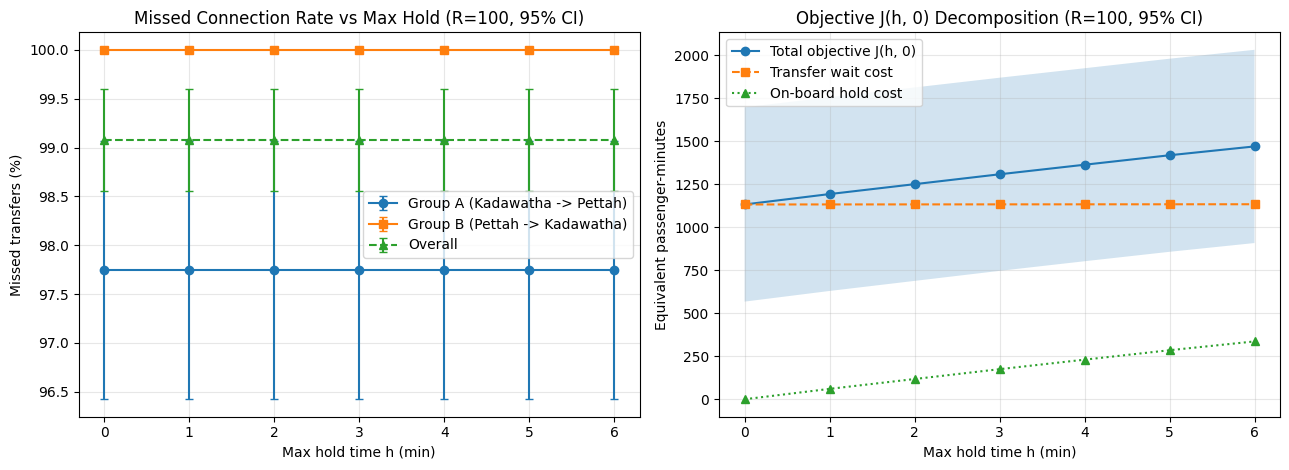

In [22]:
R_PREVIEW = 100
HOLD_GRID_MIN = [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0]

rep_seeds = root_seed_sequence.spawn(R_PREVIEW)
precomputed_days = [precompute_day_inputs(s) for s in rep_seeds]

sweep_rows = []
for h_val in HOLD_GRID_MIN:
    policy = "none" if h_val == 0.0 else "schedule"
    miss_a_arr, miss_b_arr, miss_all_arr = [], [], []
    j_arr, wait_arr, hold_arr = [], [], []
    for day_in in precomputed_days:
        res = evaluate_day(day_in, policy=policy, hold_max_min=h_val)
        ma = (res["A"]["missed_timing"] + res["A"]["missed_capacity"]) / max(1, res["A"]["in_window_total"])
        mb = (res["B"]["missed_timing"] + res["B"]["missed_capacity"]) / max(1, res["B"]["in_window_total"])
        in_tot = res["A"]["in_window_total"] + res["B"]["in_window_total"]
        miss_tot = (res["A"]["missed_timing"] + res["A"]["missed_capacity"] + res["B"]["missed_timing"] + res["B"]["missed_capacity"]) / max(1, in_tot)
        miss_a_arr.append(100.0 * ma)
        miss_b_arr.append(100.0 * mb)
        miss_all_arr.append(100.0 * miss_tot)
        w_c = res["A"]["wait_cost"] + res["B"]["wait_cost"]
        h_c = res["A"]["hold_cost"] + res["B"]["hold_cost"]
        wait_arr.append(w_c)
        hold_arr.append(h_c)
        j_arr.append(w_c + h_c)

    def mean_ci(vals):
        arr = np.asarray(vals, dtype=float)
        m = float(np.mean(arr))
        ci = 1.96 * float(np.std(arr, ddof=1)) / np.sqrt(len(arr))
        return m, ci

    ma_m, ma_ci = mean_ci(miss_a_arr)
    mb_m, mb_ci = mean_ci(miss_b_arr)
    mall_m, mall_ci = mean_ci(miss_all_arr)
    j_m, j_ci = mean_ci(j_arr)
    w_m, _ = mean_ci(wait_arr)
    hc_m, _ = mean_ci(hold_arr)
    sweep_rows.append({
        "hold_max_min": h_val,
        "miss_A_pct": ma_m, "miss_A_ci": ma_ci,
        "miss_B_pct": mb_m, "miss_B_ci": mb_ci,
        "miss_all_pct": mall_m, "miss_all_ci": mall_ci,
        "J_mean": j_m, "J_ci": j_ci,
        "wait_cost": w_m, "hold_cost": hc_m,
    })

sweep_df = pd.DataFrame(sweep_rows)
print(sweep_df[["hold_max_min", "miss_A_pct", "miss_B_pct", "miss_all_pct", "J_mean", "J_ci"]].round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax1 = axes[0]
ax1.errorbar(sweep_df["hold_max_min"], sweep_df["miss_A_pct"], yerr=sweep_df["miss_A_ci"], marker="o", capsize=3, label="Group A (Kadawatha -> Pettah)")
ax1.errorbar(sweep_df["hold_max_min"], sweep_df["miss_B_pct"], yerr=sweep_df["miss_B_ci"], marker="s", capsize=3, label="Group B (Pettah -> Kadawatha)")
ax1.errorbar(sweep_df["hold_max_min"], sweep_df["miss_all_pct"], yerr=sweep_df["miss_all_ci"], marker="^", linestyle="--", capsize=3, label="Overall")
ax1.set_xlabel("Max hold time h (min)")
ax1.set_ylabel("Missed transfers (%)")
ax1.set_title(f"Missed Connection Rate vs Max Hold (R={R_PREVIEW}, 95% CI)")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2 = axes[1]
ax2.plot(sweep_df["hold_max_min"], sweep_df["J_mean"], marker="o", label="Total objective J(h, 0)")
ax2.fill_between(sweep_df["hold_max_min"], sweep_df["J_mean"] - sweep_df["J_ci"], sweep_df["J_mean"] + sweep_df["J_ci"], alpha=0.2)
ax2.plot(sweep_df["hold_max_min"], sweep_df["wait_cost"], marker="s", linestyle="--", label="Transfer wait cost")
ax2.plot(sweep_df["hold_max_min"], sweep_df["hold_cost"], marker="^", linestyle=":", label="On-board hold cost")
ax2.set_xlabel("Max hold time h (min)")
ax2.set_ylabel("Equivalent passenger-minutes")
ax2.set_title(f"Objective J(h, 0) Decomposition (R={R_PREVIEW}, 95% CI)")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

## 6. Discussion and limitations

*Provenance: AI-generated.*

## 7. References

*Provenance: AI-generated.*